In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from prophet import Prophet

import joblib

d:\1_CDAC_notes\Project\autonomous-ecommerce-agent\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv("orders_15000.csv")

print(df.shape)

df.head()

(15000, 10)


,order_id,customer_id,customer_name,product_name,order_date,expected_delivery_date,actual_delivery_date,status,delay_days,warehouse
0,1,9449,Jairaj Badal,Bluetooth Headphones,2026-02-21,2026-02-26,2026-02-25,Delivered,0,Delhi
1,2,5385,Zehaan Kulkarni,Action Camera,2025-03-17,2025-03-23,2025-03-23,Delivered,0,Hyderabad
2,3,4186,Chaitaly Bora,Mechanical Pencil,2024-11-15,2024-11-19,2024-11-18,Delivered,0,Hyderabad
3,4,6933,Aashi Goyal,Action Camera,2026-04-19,2026-04-26,2026-04-26,Delivered,0,Hyderabad
4,5,1463,Saksham Date,Microphone,2024-08-15,2024-08-19,2024-08-18,Delivered,0,Kolkata


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   order_id                15000 non-null  int64
 1   customer_id             15000 non-null  int64
 2   customer_name           15000 non-null  str  
 3   product_name            15000 non-null  str  
 4   order_date              15000 non-null  str  
 5   expected_delivery_date  15000 non-null  str  
 6   actual_delivery_date    15000 non-null  str  
 7   status                  15000 non-null  str  
 8   delay_days              15000 non-null  int64
 9   warehouse               15000 non-null  str  
dtypes: int64(3), str(7)
memory usage: 2.2 MB


In [4]:
df["order_date"] = pd.to_datetime(df["order_date"])

df["expected_delivery_date"] = pd.to_datetime(
    df["expected_delivery_date"]
)

df["actual_delivery_date"] = pd.to_datetime(
    df["actual_delivery_date"]
)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   order_id                15000 non-null  int64         
 1   customer_id             15000 non-null  int64         
 2   customer_name           15000 non-null  str           
 3   product_name            15000 non-null  str           
 4   order_date              15000 non-null  datetime64[us]
 5   expected_delivery_date  15000 non-null  datetime64[us]
 6   actual_delivery_date    15000 non-null  datetime64[us]
 7   status                  15000 non-null  str           
 8   delay_days              15000 non-null  int64         
 9   warehouse               15000 non-null  str           
dtypes: datetime64[us](3), int64(3), str(4)
memory usage: 1.7 MB


In [5]:
print("Minimum Date:")
print(df["order_date"].min())

print("\nMaximum Date:")
print(df["order_date"].max())

Minimum Date:
2023-07-03 00:00:00

Maximum Date:
2026-07-02 00:00:00


In [6]:
# Keep only delayed orders
delayed_df = df[
    df["status"] == "Delayed"
]

# Group by month
monthly_delays = (

    delayed_df

    .groupby(
        pd.Grouper(
            key="order_date",
            freq="MS"   # Month Start
        )
    )

    .size()

    .reset_index(name="delayed_orders")
)

monthly_delays

,order_date,delayed_orders
0,2023-07-01,85
1,2023-08-01,81
2,2023-09-01,88
3,2023-10-01,78
4,2023-11-01,69
5,2023-12-01,80
6,2024-01-01,78
7,2024-02-01,91
8,2024-03-01,88
9,2024-04-01,91


In [7]:
prophet_df = monthly_delays.rename(
    columns={
        "order_date": "ds",
        "delayed_orders": "y"
    }
)

prophet_df

,ds,y
0,2023-07-01,85
1,2023-08-01,81
2,2023-09-01,88
3,2023-10-01,78
4,2023-11-01,69
5,2023-12-01,80
6,2024-01-01,78
7,2024-02-01,91
8,2024-03-01,88
9,2024-04-01,91


In [14]:
monthly_delays.to_csv(
    "D:\\1_CDAC_notes\\Project\\autonomous-ecommerce-agent\\prophet_model\\delay_history.csv",
    index=False
)

In [21]:
model = Prophet(

    yearly_seasonality=True,

    weekly_seasonality=False,

    daily_seasonality=False
)

model.fit(prophet_df)

11:51:46 - cmdstanpy - INFO - Chain [1] start processing
11:51:46 - cmdstanpy - INFO - Chain [1] done processing


In [22]:
future = model.make_future_dataframe(
    periods=1,
    freq="MS"
)

forecast = model.predict(future)

In [23]:
forecast.tail(1)[

    [

        "ds",

        "yhat",

        "yhat_lower",

        "yhat_upper"

    ]

]

,ds,yhat,yhat_lower,yhat_upper
37,2026-08-01,75.90959,59.769764,91.820547


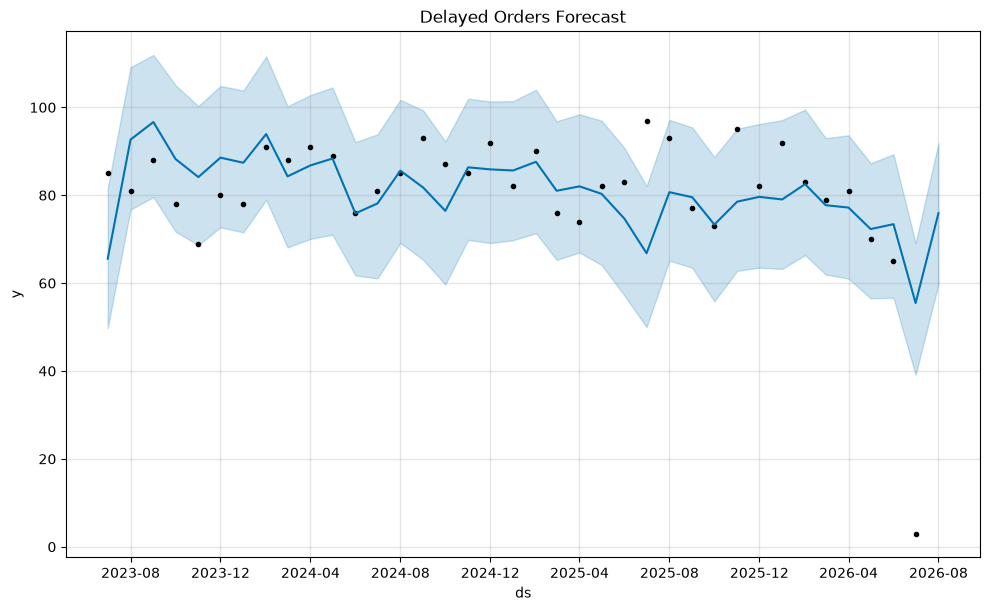

In [24]:
import matplotlib.pyplot as plt


fig = model.plot(

    forecast

)


plt.title(

    "Delayed Orders Forecast"

)

plt.show()

In [25]:
monthly_delays = monthly_delays[
    monthly_delays["delayed_orders"] > 10
]

monthly_delays.tail()

,order_date,delayed_orders
31,2026-02-01,83
32,2026-03-01,79
33,2026-04-01,81
34,2026-05-01,70
35,2026-06-01,65


In [26]:
prophet_df = monthly_delays.rename(
    columns={
        "order_date": "ds",
        "delayed_orders": "y"
    }
)

prophet_df.tail()

,ds,y
31,2026-02-01,83
32,2026-03-01,79
33,2026-04-01,81
34,2026-05-01,70
35,2026-06-01,65


In [27]:
from prophet import Prophet

model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

model.fit(prophet_df)

13:53:35 - cmdstanpy - INFO - Chain [1] start processing
13:53:35 - cmdstanpy - INFO - Chain [1] done processing


In [28]:
future = model.make_future_dataframe(
    periods=1,
    freq="MS"
)

forecast = model.predict(future)

forecast.tail(1)[
    ["ds", "yhat", "yhat_lower", "yhat_upper"]
]

,ds,yhat,yhat_lower,yhat_upper
36,2026-07-01,90.369324,82.741232,98.432065


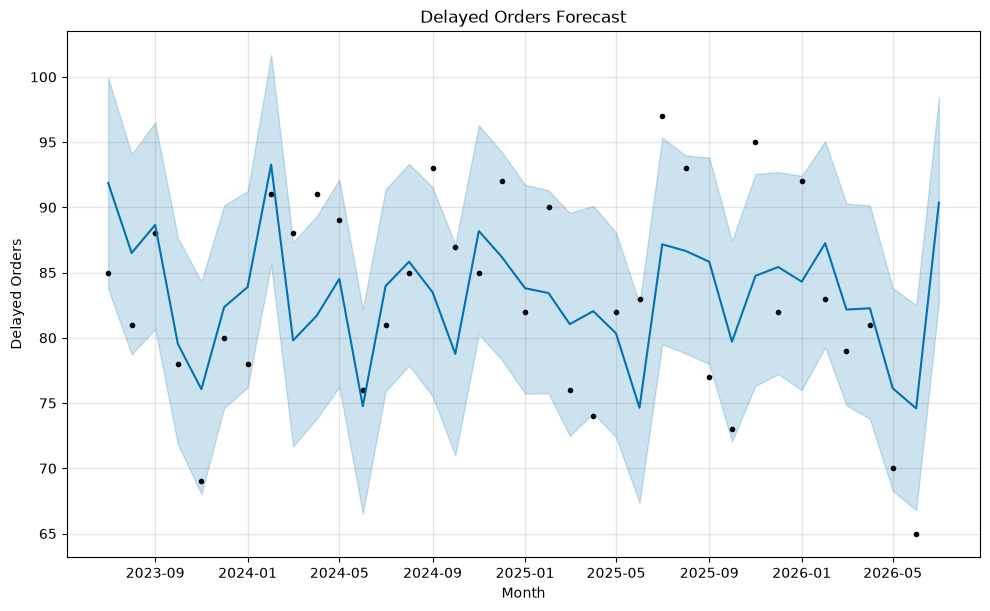

In [29]:
import matplotlib.pyplot as plt

fig = model.plot(forecast)

plt.title(
    "Delayed Orders Forecast"
)

plt.xlabel("Month")

plt.ylabel("Delayed Orders")

plt.show()

In [30]:
import joblib

joblib.dump(
    model,
    "delay_forecast.pkl"
)

print(
    "Model saved successfully!"
)

Model saved successfully!
